In [4]:
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Ensure inline plotting
%matplotlib inline


In [5]:
file_path = '/Users/anand/Documents/Datasets/car_price_dataset.csv'
df = pd.read_csv(file_path)

# Display the first few rows of the dataset
df.head()

,Brand,Model,Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Price
0,Kia,Rio,2020,4.2,Diesel,Manual,289944,3,5,8501
1,Chevrolet,Malibu,2012,2.0,Hybrid,Automatic,5356,2,3,12092
2,Mercedes,GLA,2020,4.2,Diesel,Automatic,231440,4,2,11171
3,Audi,Q5,2023,2.0,Electric,Manual,160971,2,1,11780
4,Volkswagen,Golf,2003,2.6,Hybrid,Semi-Automatic,286618,3,3,2867


In [6]:
# Check for missing values
df.isnull().sum()

Brand           0
Model           0
Year            0
Engine_Size     0
Fuel_Type       0
Transmission    0
Mileage         0
Doors           0
Owner_Count     0
Price           0
dtype: int64

In [7]:
# Encode categorical variables
df_encoded = pd.get_dummies(df, columns=['Brand', 'Model', 'Fuel_Type', 'Transmission'], drop_first=True)

# Display the first few rows of the encoded dataset
df_encoded.head()


,Year,Engine_Size,Mileage,Doors,Owner_Count,Price,Brand_BMW,Brand_Chevrolet,Brand_Ford,Brand_Honda,...,Model_Sonata,Model_Sportage,Model_Tiguan,Model_Tucson,Model_X5,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual,Transmission_Semi-Automatic
0,2020,4.2,289944,3,5,8501,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,2012,2.0,5356,2,3,12092,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
2,2020,4.2,231440,4,2,11171,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,2023,2.0,160971,2,1,11780,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
4,2003,2.6,286618,3,3,2867,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True


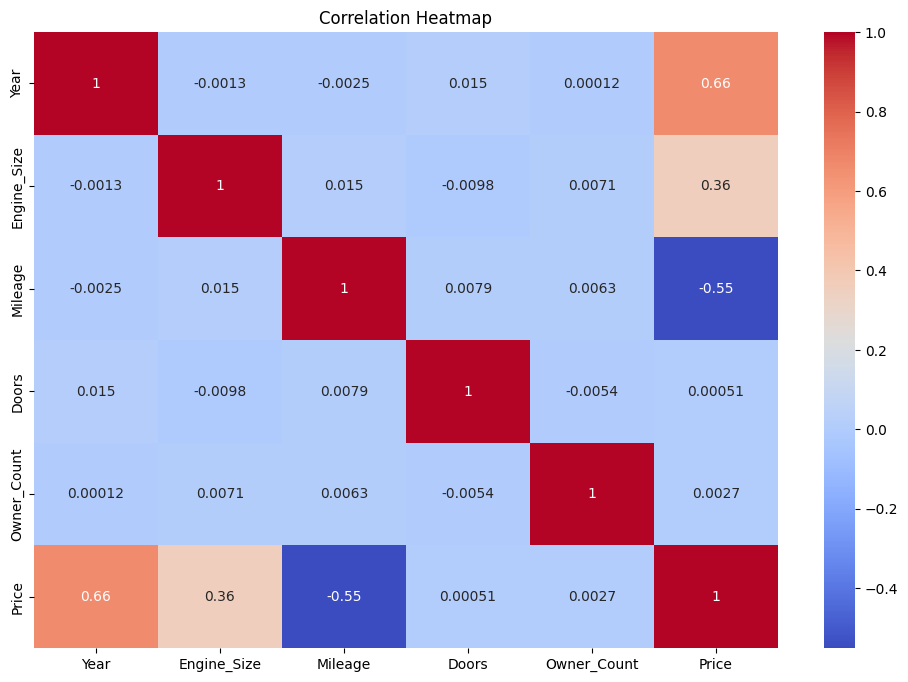

In [8]:
# Correlation heatmap
numeric_df = df_encoded.select_dtypes(include=[np.number])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


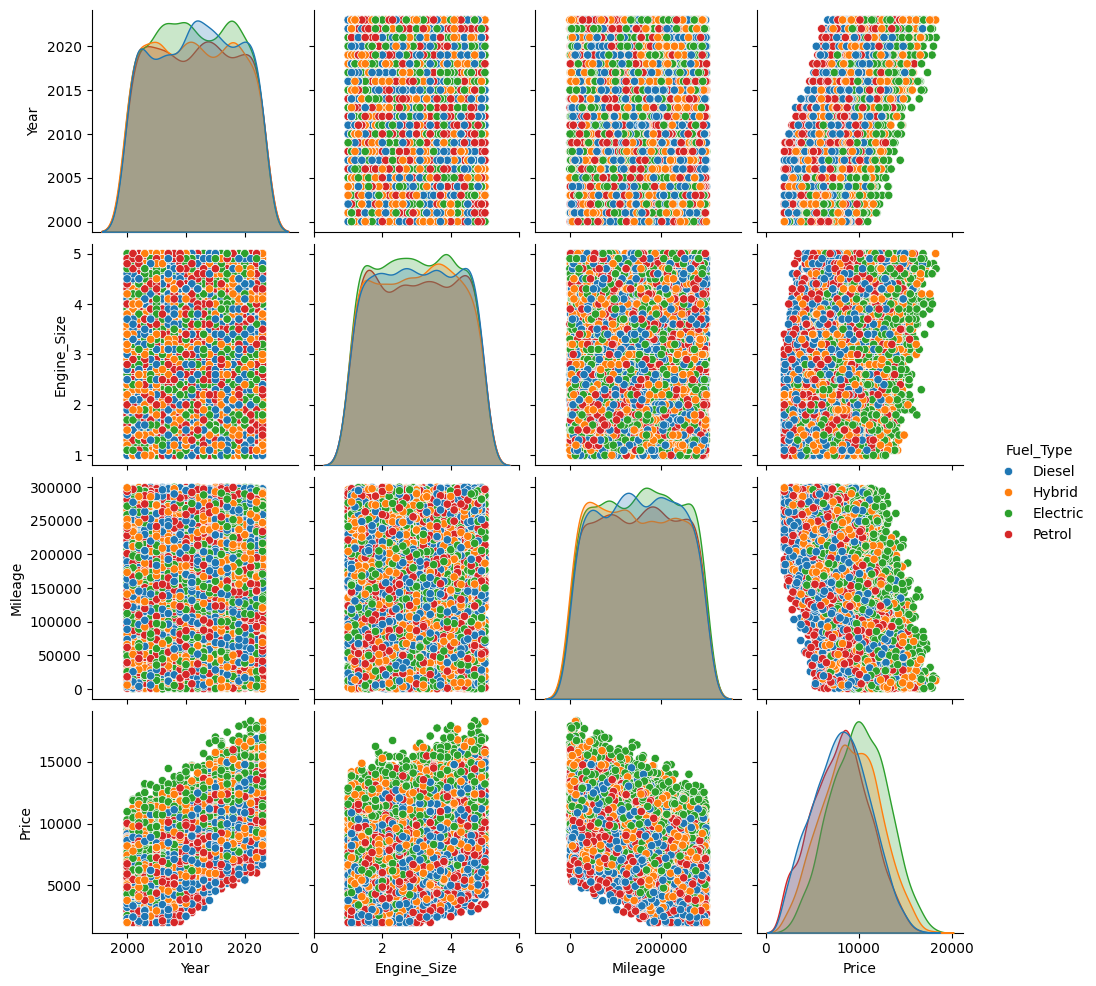

In [9]:
# Pair plot
sns.pairplot(df, vars=['Year', 'Engine_Size', 'Mileage', 'Price'], hue='Fuel_Type')
plt.show()

In [10]:
# Example of feature engineering: creating a new feature for car age
# Encode categorical variables
import pandas as pd
file_path = '/Users/anand/Documents/Datasets/car_price_dataset.csv'
df = pd.read_csv(file_path)
df_encoded = pd.get_dummies(df, columns=['Brand', 'Model', 'Fuel_Type', 'Transmission'], drop_first=True)

# Display the first few rows of the encoded dataset
df_encoded.head()
df_encoded['Car_Age'] = 2023 - df_encoded['Year']

# Drop the original 'Year' column
df_encoded.drop('Year', axis=1, inplace=True)

In [11]:
# Define features and target variable
from sklearn.model_selection import train_test_split

X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [12]:
# Make predictions
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')

Mean Squared Error: 4213.922497904813
R-squared: 0.999541357336514


In [13]:
print(y_test)

6252     2000
4684    11164
1731    14630
4742     7334
4521    10127
        ...  
6412     4681
8285    12839
7853     8124
1095     6709
6929    11855
Name: Price, Length: 2000, dtype: int64


In [14]:
print(y_pred)

[ 1691.4462538  11149.12802229 14601.97132663 ...  8131.16770087
  6724.65163352 11842.43505306]


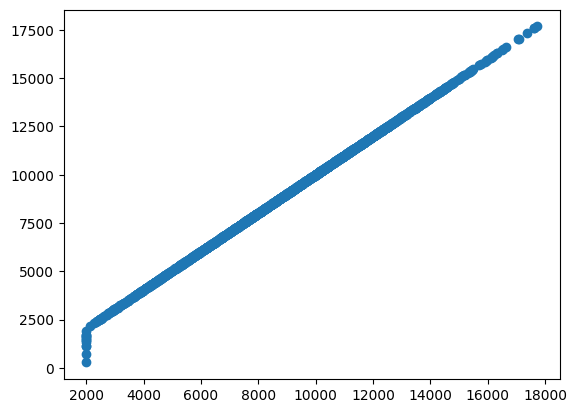

In [15]:
plt.scatter(y_test, y_pred)

In [16]:
print(X_test)

      Engine_Size  Mileage  Doors  Owner_Count  Brand_BMW  Brand_Chevrolet  \
6252          1.2   257760      5            5       True            False   
4684          2.9   111790      5            3      False            False   
1731          5.0    13473      5            4      False            False   
4742          3.8   133298      4            5      False            False   
4521          1.3    18611      3            5      False            False   
...           ...      ...    ...          ...        ...              ...   
6412          4.0   200943      2            5      False            False   
8285          2.9    13036      4            3      False            False   
7853          3.8   138757      2            1      False            False   
1095          3.1   189547      2            5      False             True   
6929          3.5    77213      4            5      False            False   

      Brand_Ford  Brand_Honda  Brand_Hyundai  Brand_Kia  ...  M